In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks
import maze_helper as mh




L_maze.txt


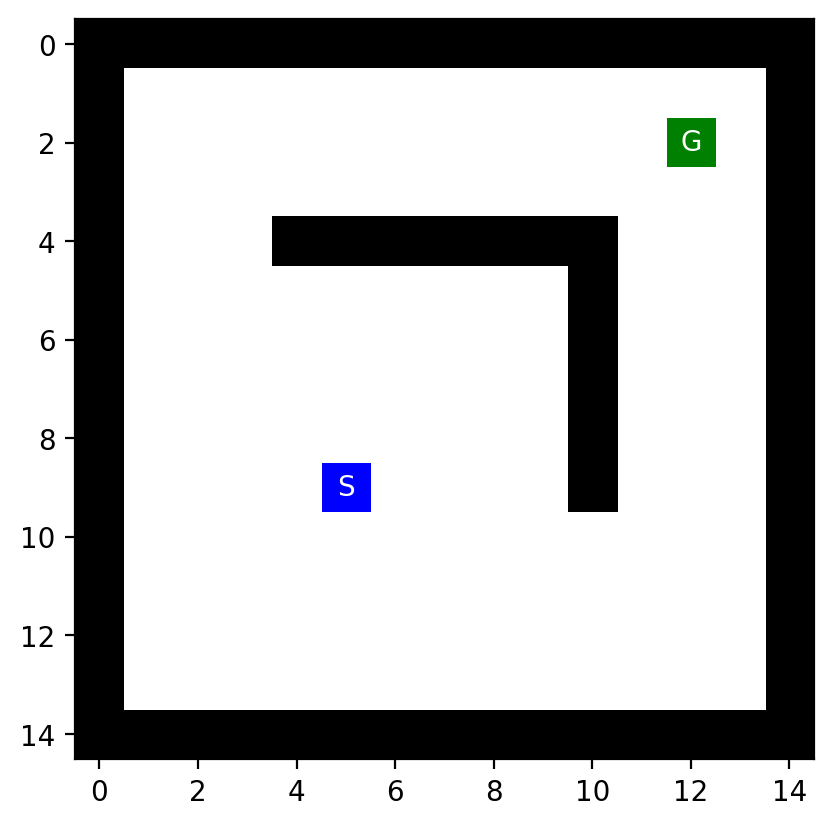

empty_maze.txt


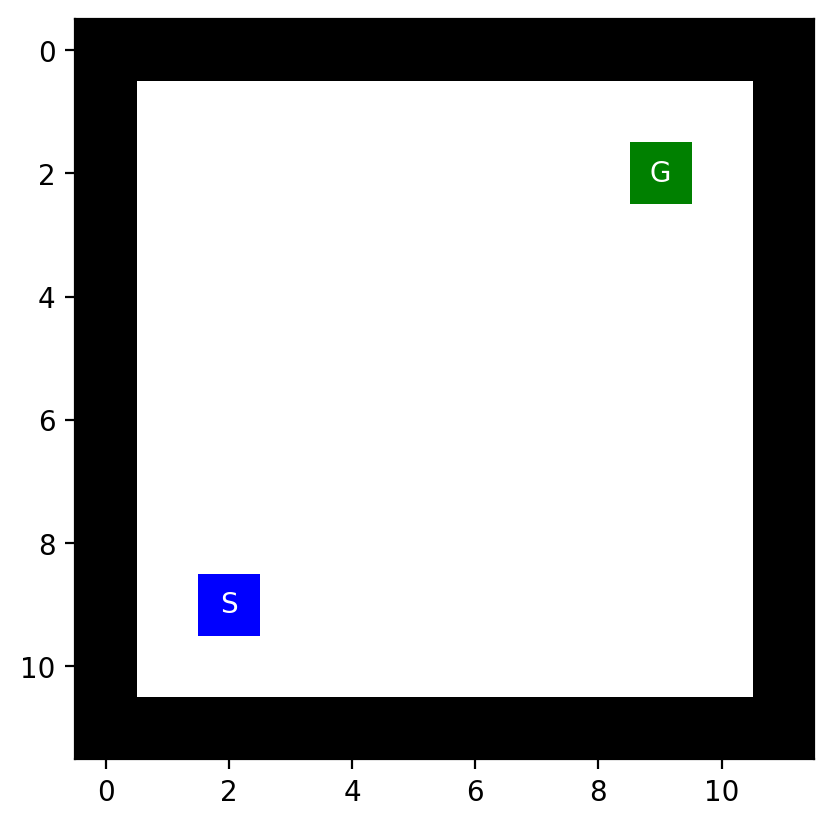

empty_maze_2.txt


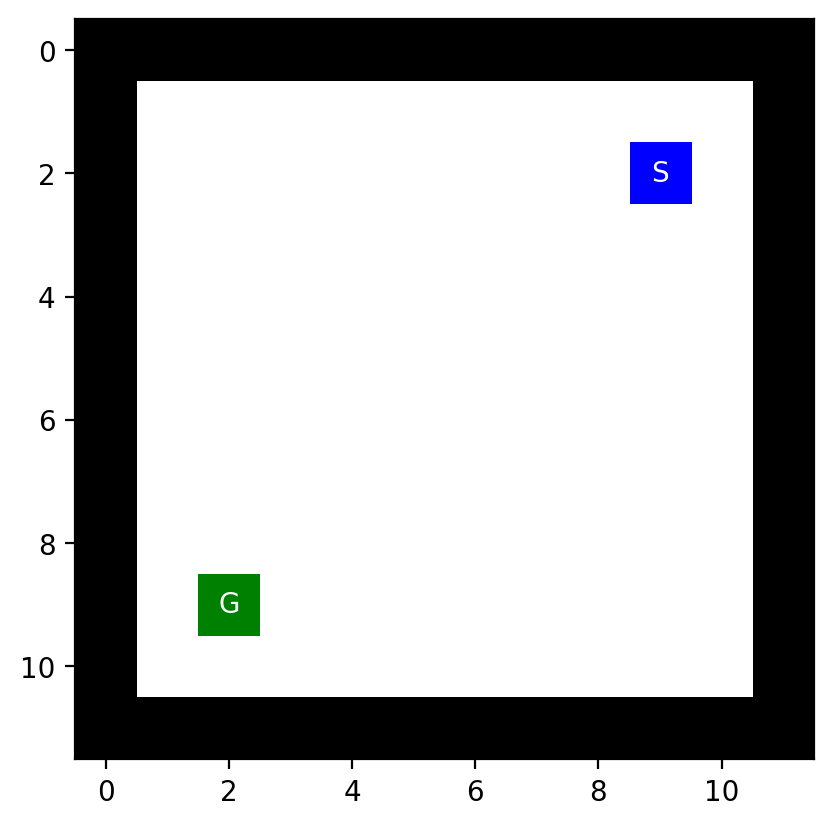

large_maze.txt


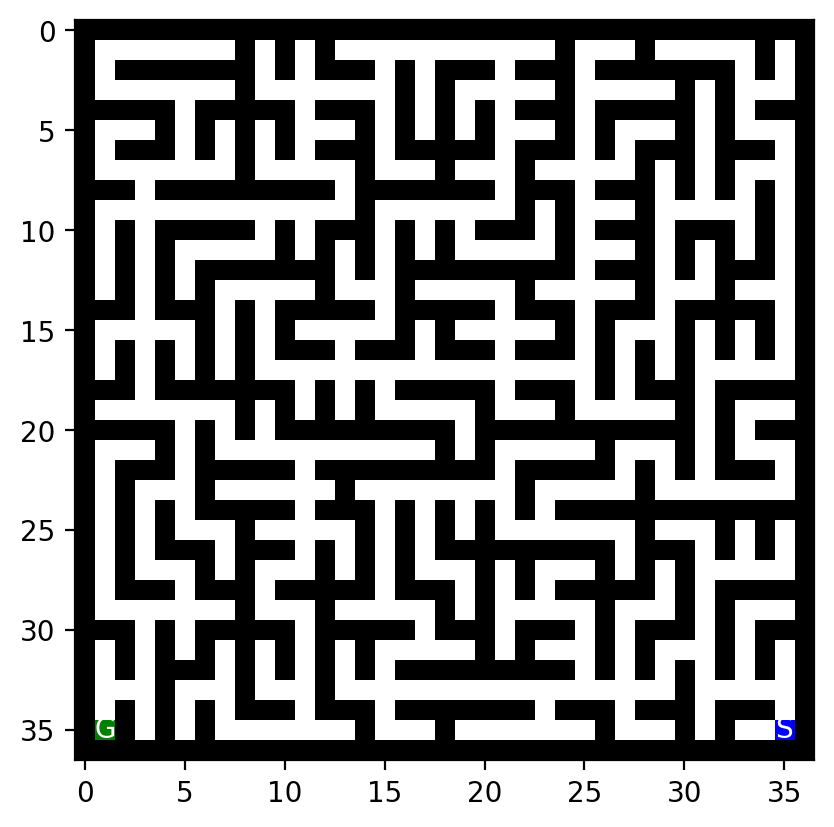

loops_maze.txt


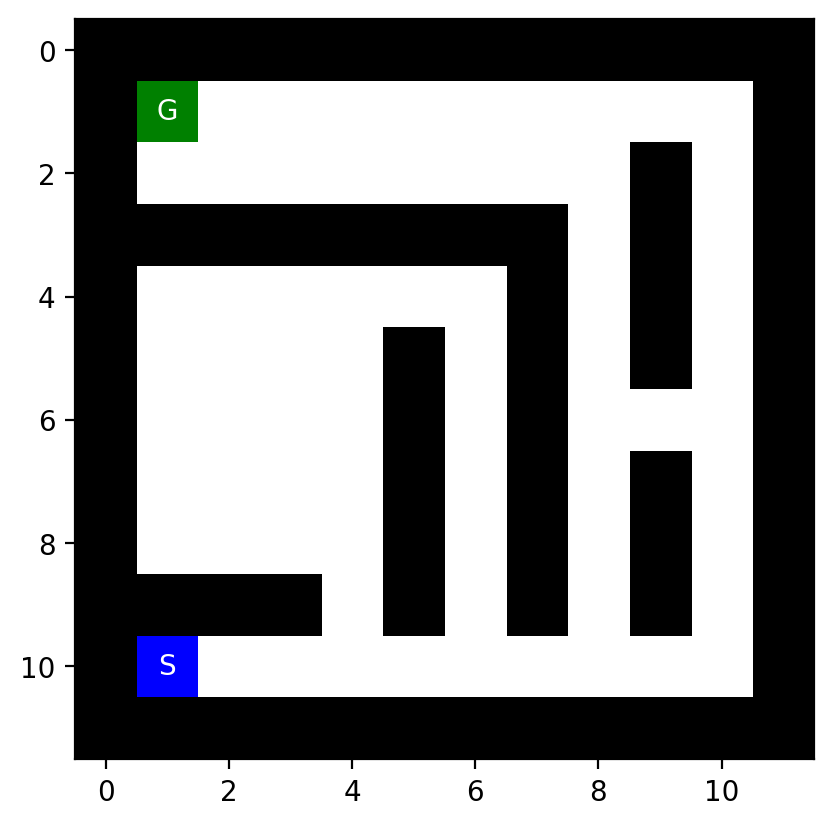

medium_maze.txt


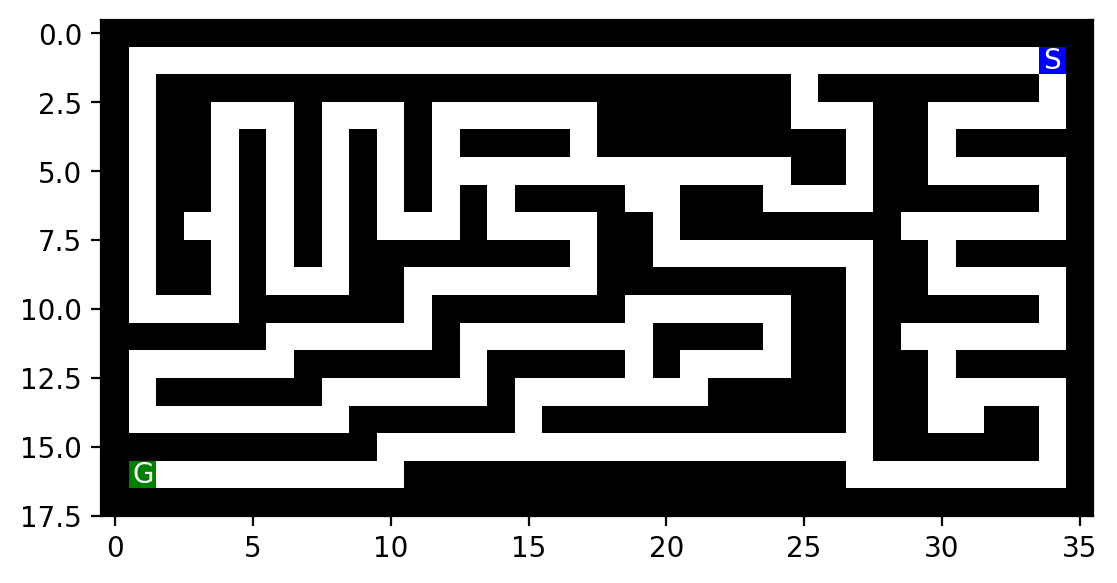

open_maze.txt


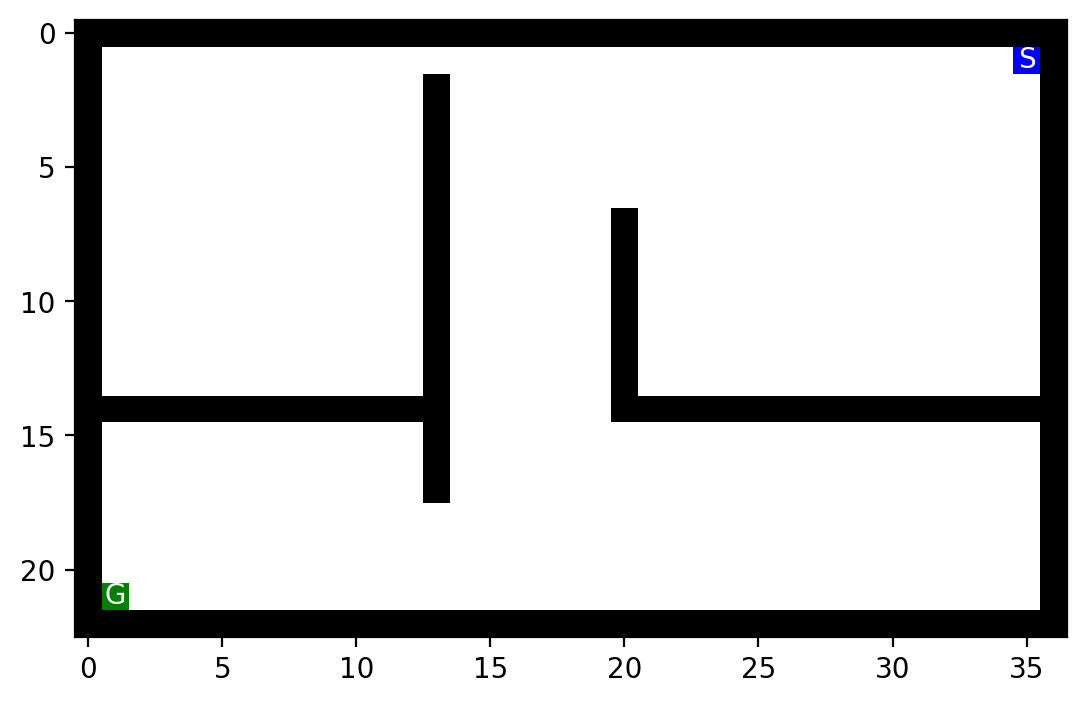

small_maze.txt


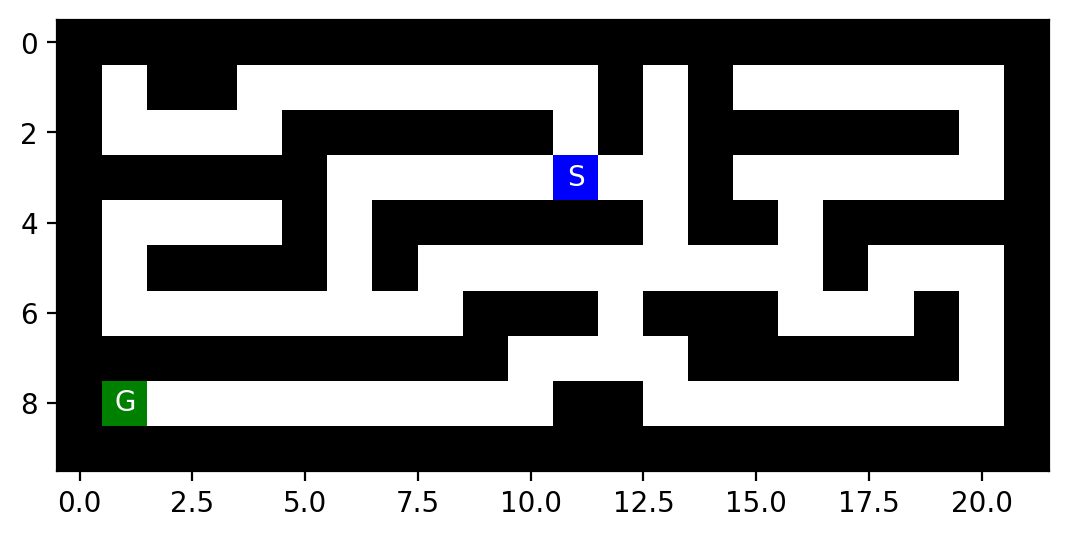

In [2]:
import os

def list_mazes(directory):
    txt_files = []
    for filename in os.listdir(directory):
        if filename.endswith(".txt"):
            txt_files.append(filename)
    txt_files.sort()
    return txt_files

mazes = list_mazes(".")

for maze_file in mazes:
    with open(maze_file, "r") as f:
        maze_str = f.read()
    maze = mh.parse_maze(maze_str)
    
    print(maze_file)
    
    mh.show_maze(maze)

### Lưu hình và thống kê các mê cung

Cell dưới lưu từng mê cung thành ảnh PNG, một ảnh tổng hợp và bảng thống kê (kích thước, số ô trống $n$, vị trí `S`/`G`, khoảng cách Manhattan) vào thư mục `results_ex3/`.

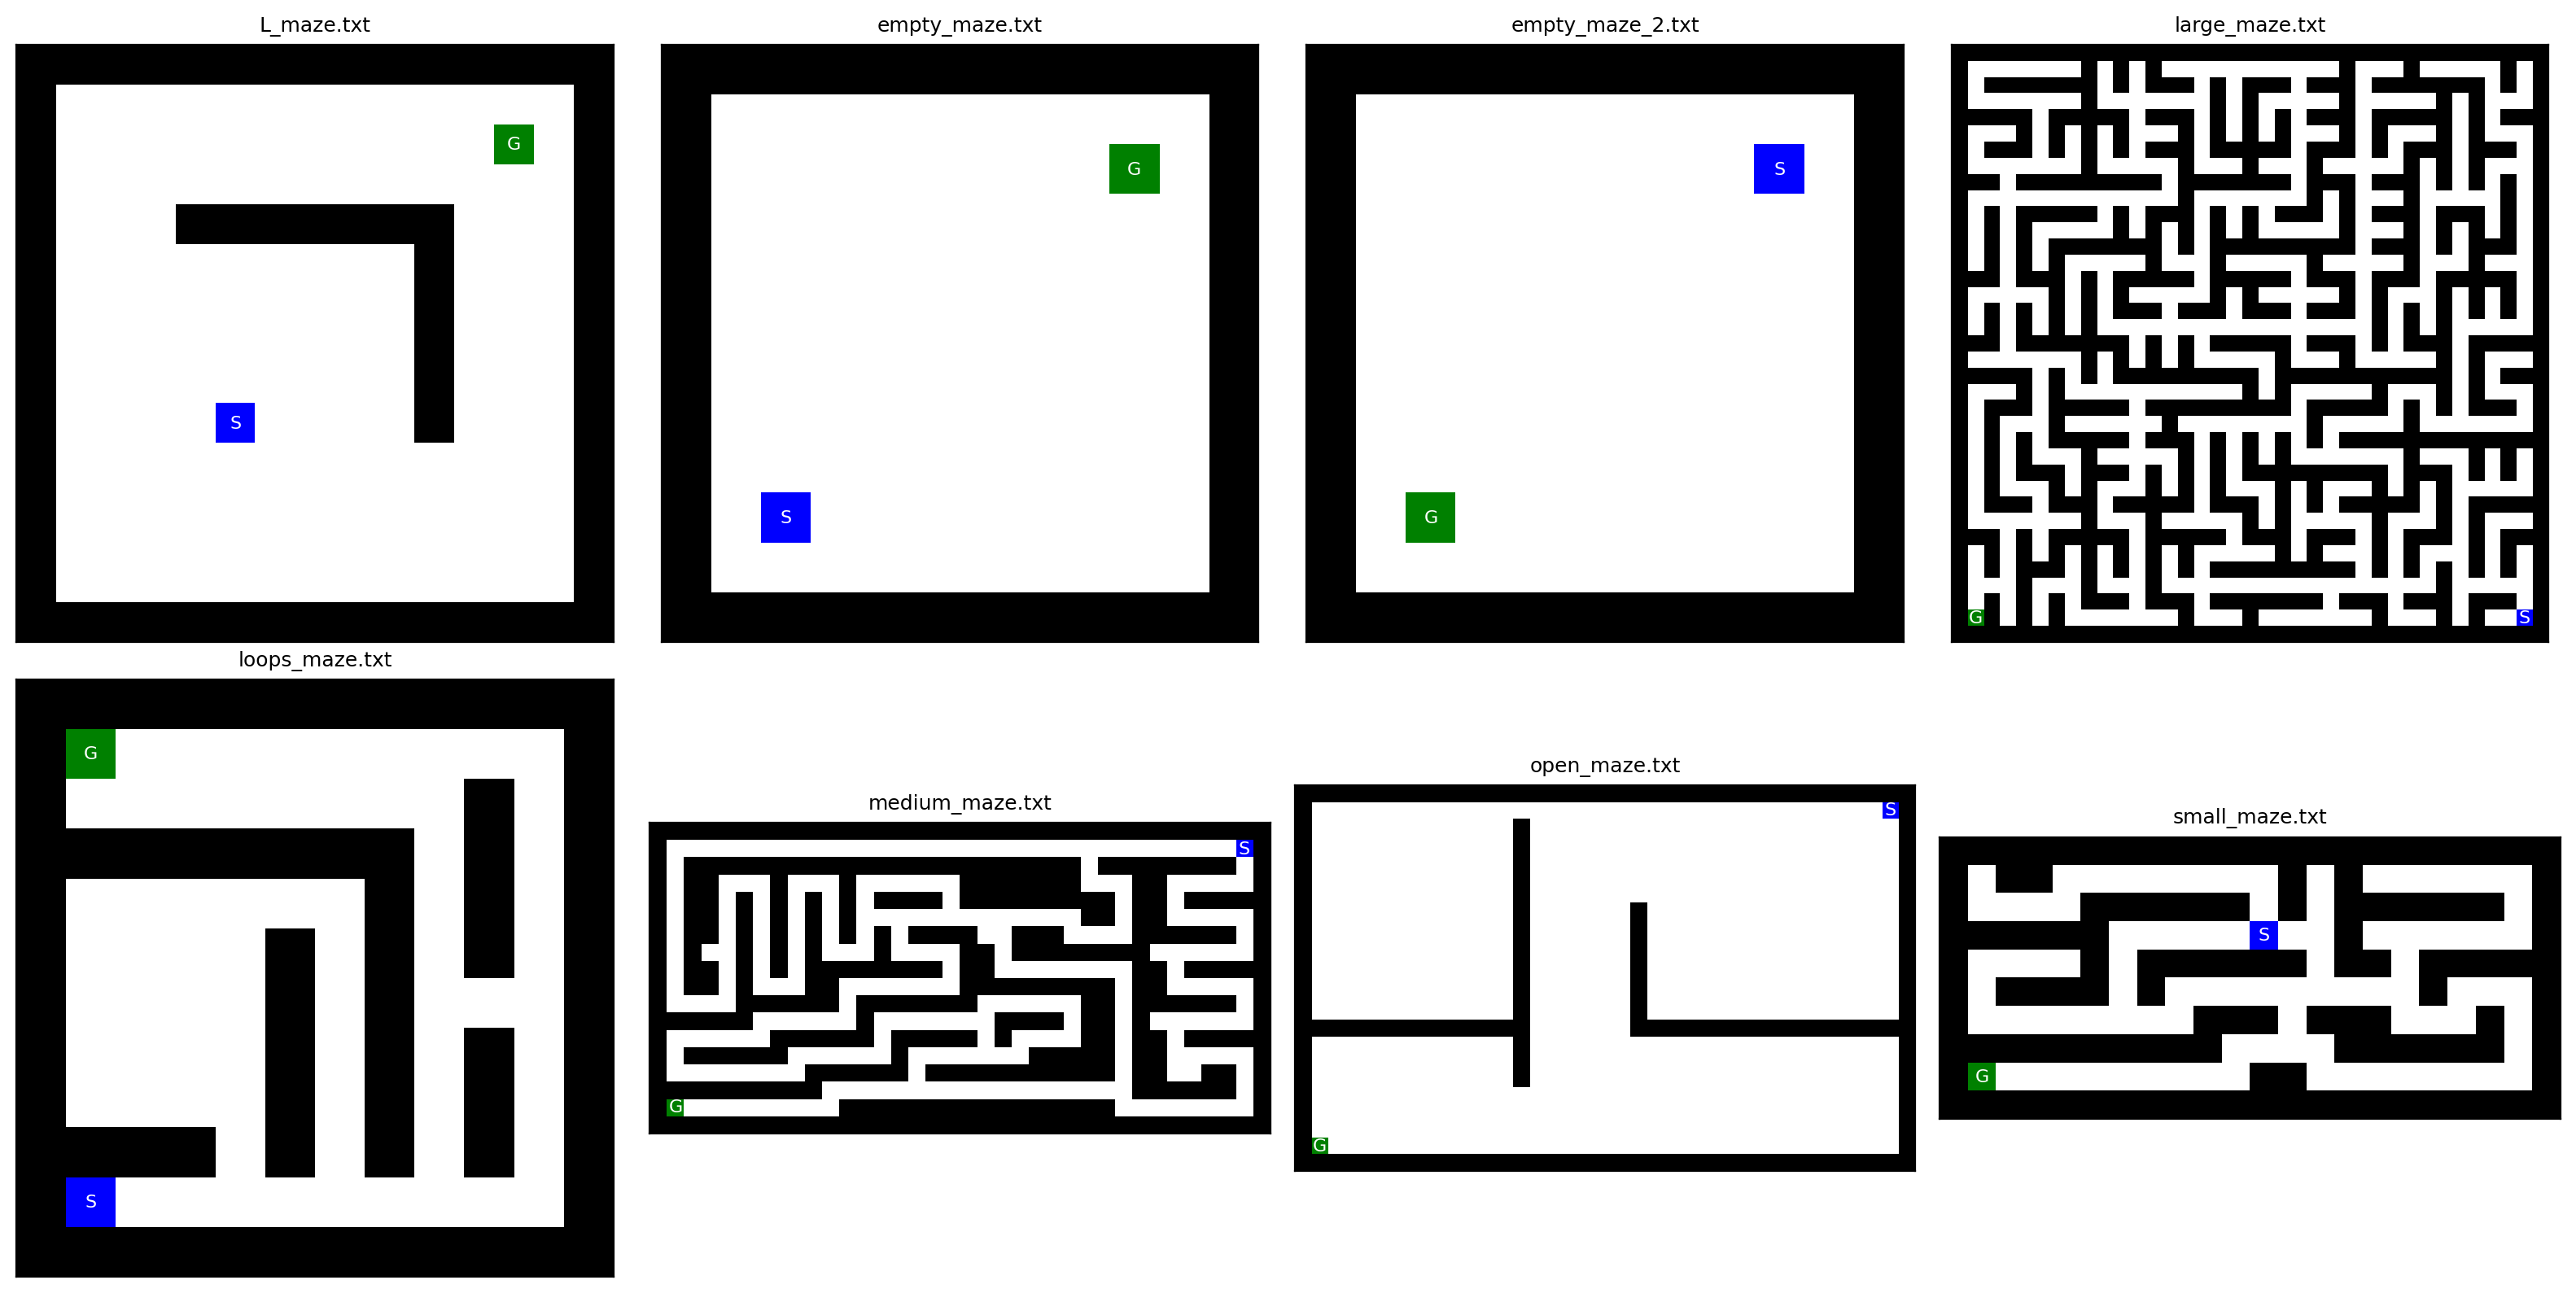

Đã lưu: 10 file vào results_ex3/


,maze,kích thước,# ô trống (n),"S (row, col)","G (row, col)",Manhattan S→G
0,L_maze.txt,15x15,157,"(9, 5)","(2, 12)",14
1,empty_maze.txt,12x12,100,"(9, 2)","(2, 9)",14
2,empty_maze_2.txt,12x12,100,"(2, 9)","(9, 2)",14
3,large_maze.txt,37x37,647,"(35, 35)","(35, 1)",34
4,loops_maze.txt,12x12,72,"(10, 1)","(1, 1)",9
5,medium_maze.txt,18x36,274,"(1, 34)","(16, 1)",48
6,open_maze.txt,23x37,684,"(1, 35)","(21, 1)",54
7,small_maze.txt,10x22,94,"(3, 11)","(8, 1)",15


In [3]:
# ---- Lưu ảnh từng mê cung + bảng thống kê vào results_ex3/ ----
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors

os.makedirs("results_ex3", exist_ok=True)
CMAP = colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
CODE = {" ": 0, "X": 1, "S": 2, "G": 3, "P": 4, ".": 5, "F": 6}

def draw(ax, maze, title):
    ax.imshow(np.array([[CODE[ch] for ch in row] for row in maze]), cmap=CMAP,
              norm=colors.BoundaryNorm(range(8), 7))
    for label in "SG":
        for r, c in np.argwhere(maze == label):
            ax.text(c, r, label, color="white", ha="center", va="center", fontsize=8)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

stats, loaded = [], {}
for maze_file in mazes:
    with open(maze_file, "r") as f:
        m = mh.parse_maze(f.read())
    loaded[maze_file] = m
    s, g = mh.find_pos(m, "S"), mh.find_pos(m, "G")
    stats.append({"maze": maze_file, "kích thước": f"{m.shape[0]}x{m.shape[1]}",
                  "# ô trống (n)": int((m != "X").sum()), "S (row, col)": (int(s[0]), int(s[1])),
                  "G (row, col)": (int(g[0]), int(g[1])),
                  "Manhattan S→G": int(abs(s[0] - g[0]) + abs(s[1] - g[1]))})
    fig, ax = plt.subplots(figsize=(5, 5)); draw(ax, m, maze_file)
    fig.savefig(f"results_ex3/{maze_file.replace('.txt', '.png')}", dpi=150, bbox_inches="tight")
    plt.close(fig)

# Ảnh tổng hợp tất cả mê cung trong một hình
cols = 4
rows_ = -(-len(loaded) // cols)
fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 4 * rows_))
for ax in axes.ravel(): ax.axis("off")
for ax, (name, m) in zip(axes.ravel(), loaded.items()):
    ax.axis("on"); draw(ax, m, name)
fig.tight_layout(); fig.savefig("results_ex3/tat_ca_me_cung.png", dpi=150); plt.show()

stats_df = pd.DataFrame(stats)
stats_df.to_csv("results_ex3/thong_ke_me_cung.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", len(os.listdir("results_ex3")), "file vào results_ex3/")
stats_df